**Hotel Booking And Cancellation Analysis**

The main aim of the project is to understand hotel booking patterns and identify factors associated with booking cancellation

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [ ]:
df=pd.read_csv('/content/hotel_bookings.csv')
df

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.00,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.00,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.00,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.00,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.00,0,1,Check-Out,2015-07-03
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
119385,City Hotel,0,23,2017,August,35,30,2,5,2,...,No Deposit,394.0,NaN,0,Transient,96.14,0,0,Check-Out,2017-09-06
119386,City Hotel,0,102,2017,August,35,31,2,5,3,...,No Deposit,9.0,NaN,0,Transient,225.43,0,2,Check-Out,2017-09-07
119387,City Hotel,0,34,2017,August,35,31,2,5,2,...,No Deposit,9.0,NaN,0,Transient,157.71,0,4,Check-Out,2017-09-07
119388,City Hotel,0,109,2017,August,35,31,2,5,2,...,No Deposit,89.0,NaN,0,Transient,104.40,0,0,Check-Out,2017-09-07


In [ ]:
df.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


In [ ]:
df.tail()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
119385,City Hotel,0,23,2017,August,35,30,2,5,2,...,No Deposit,394.0,NaN,0,Transient,96.14,0,0,Check-Out,2017-09-06
119386,City Hotel,0,102,2017,August,35,31,2,5,3,...,No Deposit,9.0,NaN,0,Transient,225.43,0,2,Check-Out,2017-09-07
119387,City Hotel,0,34,2017,August,35,31,2,5,2,...,No Deposit,9.0,NaN,0,Transient,157.71,0,4,Check-Out,2017-09-07
119388,City Hotel,0,109,2017,August,35,31,2,5,2,...,No Deposit,89.0,NaN,0,Transient,104.40,0,0,Check-Out,2017-09-07
119389,City Hotel,0,205,2017,August,35,29,2,7,2,...,No Deposit,9.0,NaN,0,Transient,151.20,0,2,Check-Out,2017-09-07


In [ ]:
df.shape

(119390, 32)

In [ ]:
df.columns

Index(['hotel', 'is_canceled', 'lead_time', 'arrival_date_year',
       'arrival_date_month', 'arrival_date_week_number',
       'arrival_date_day_of_month', 'stays_in_weekend_nights',
       'stays_in_week_nights', 'adults', 'children', 'babies', 'meal',
       'country', 'market_segment', 'distribution_channel',
       'is_repeated_guest', 'previous_cancellations',
       'previous_bookings_not_canceled', 'reserved_room_type',
       'assigned_room_type', 'booking_changes', 'deposit_type', 'agent',
       'company', 'days_in_waiting_list', 'customer_type', 'adr',
       'required_car_parking_spaces', 'total_of_special_requests',
       'reservation_status', 'reservation_status_date'],
      dtype='object')

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  object 
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  object 
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal            

In [ ]:
df.isna().sum()

,0
hotel,0
is_canceled,0
lead_time,0
arrival_date_year,0
arrival_date_month,0
arrival_date_week_number,0
arrival_date_day_of_month,0
stays_in_weekend_nights,0
stays_in_week_nights,0
adults,0


In [ ]:
df.duplicated().sum()

np.int64(31994)

In [ ]:
df=df.drop_duplicates()

In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df=df.drop('company', axis=1)

In [ ]:
df['children'] = df['children'].fillna(df['children'].median())

In [ ]:
df['agent'] = df['agent'].fillna(0)   #had null,so changed it to zero

In [ ]:
df['country']=df['country'].fillna('Unknown')    #had null,changed to unknown

In [ ]:
lst = ['hotel', 'is_canceled', 'lead_time', 'arrival_date_year',
       'arrival_date_month', 'arrival_date_week_number',
       'arrival_date_day_of_month', 'stays_in_weekend_nights',
       'stays_in_week_nights', 'adults', 'children', 'babies', 'meal',
       'market_segment', 'distribution_channel', 'is_repeated_guest',
       'previous_cancellations', 'previous_bookings_not_canceled',
       'reserved_room_type', 'assigned_room_type', 'booking_changes',
       'deposit_type', 'agent', 'days_in_waiting_list',
       'customer_type', 'adr', 'required_car_parking_spaces',
       'total_of_special_requests', 'reservation_status',
       'reservation_status_date']

for i in lst:
    print(df[i].unique())
    print()

['Resort Hotel' 'City Hotel']

[0 1]

[342 737   7  13  14   0   9  85  75  23  35  68  18  37  12  72 127  78
  48  60  77  99 118  95  96  69  45  40  15  36  43  70  16 107  47 113
  90  50  93  76   3   1  10   5  17  51  71  63  62 101   2  81 368 364
 324  79  21 109 102   4  98  92  26  73 115  86  52  29  30  33  32   8
 100  44  80  97  64  39  34  27  82  94 110 111  84  66 104  28 258 112
  65  67  55  88  54 292  83 105 280 394  24 103 366 249  22  91  11 108
 106  31  87  41 304 117  59  53  58 116  42 321  38  56  49 317   6  57
  19  25 315 123  46  89  61 312 299 130  74 298 119  20 286 136 129 124
 327 131 460 140 114 139 122 137 126 120 128 135 150 143 151 132 125 157
 147 138 156 164 346 159 160 161 333 381 149 154 297 163 314 155 323 340
 356 142 328 144 336 248 302 175 344 382 146 170 166 338 167 310 148 165
 172 171 145 121 178 305 173 152 354 347 158 185 349 183 352 177 200 192
 361 207 174 330 134 350 334 283 153 197 133 241 193 235 194 261 260 216
 169 209 238 

In [ ]:
cols = ['meal', 'market_segment', 'distribution_channel']

for i in cols:
    df[i] = df[i].replace('Undefined', np.nan)
    df[i] = df[i].fillna(df[i].mode()[0])

In [ ]:
for i in lst:
    print(df[i].unique())
    print()

['Resort Hotel' 'City Hotel']

[0 1]

[342 737   7  13  14   0   9  85  75  23  35  68  18  37  12  72 127  78
  48  60  77  99 118  95  96  69  45  40  15  36  43  70  16 107  47 113
  90  50  93  76   3   1  10   5  17  51  71  63  62 101   2  81 368 364
 324  79  21 109 102   4  98  92  26  73 115  86  52  29  30  33  32   8
 100  44  80  97  64  39  34  27  82  94 110 111  84  66 104  28 258 112
  65  67  55  88  54 292  83 105 280 394  24 103 366 249  22  91  11 108
 106  31  87  41 304 117  59  53  58 116  42 321  38  56  49 317   6  57
  19  25 315 123  46  89  61 312 299 130  74 298 119  20 286 136 129 124
 327 131 460 140 114 139 122 137 126 120 128 135 150 143 151 132 125 157
 147 138 156 164 346 159 160 161 333 381 149 154 297 163 314 155 323 340
 356 142 328 144 336 248 302 175 344 382 146 170 166 338 167 310 148 165
 172 171 145 121 178 305 173 152 354 347 158 185 349 183 352 177 200 192
 361 207 174 330 134 350 334 283 153 197 133 241 193 235 194 261 260 216
 169 209 238 

In [ ]:
df['hotel'].value_counts()

,count
hotel,
City Hotel,53428
Resort Hotel,33968


In [ ]:
df.dtypes

,0
hotel,object
is_canceled,int64
lead_time,int64
arrival_date_year,int64
arrival_date_month,object
arrival_date_week_number,int64
arrival_date_day_of_month,int64
stays_in_weekend_nights,int64
stays_in_week_nights,int64
adults,int64


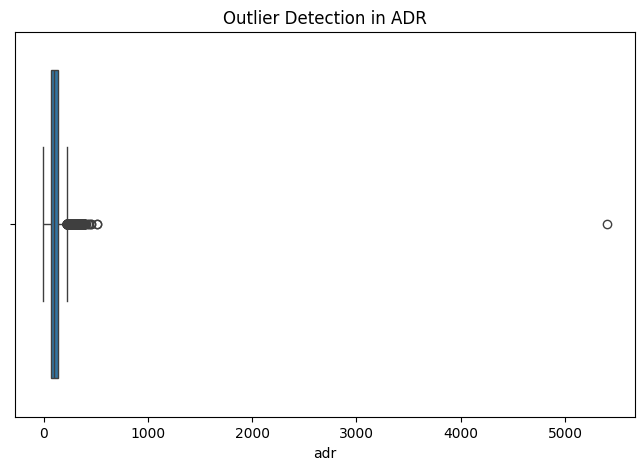

In [ ]:
#distribution of room rates and identify unusual values

plt.figure(figsize=(8, 5))
sns.boxplot(x=df['adr'])
plt.title('Outlier Detection in ADR')
plt.show()

In [ ]:
print(df.shape)

(87396, 31)


In [ ]:
#average daily rate-compare the room rate distribution in two hotels
adr_analysis = df.groupby('hotel')['adr'].agg(
    ['mean', 'median', 'min', 'max']
)

print(adr_analysis.round(2))


                mean  median   min     max
hotel                                     
City Hotel    110.99   105.3  0.00  5400.0
Resort Hotel   99.03    79.5 -6.38   508.0


In [ ]:
# cancellation rate by customer type-compare cancellation patterns amoung customer groups

customer_cancellation = df.groupby('customer_type')['is_canceled'].agg(
    ['count', 'mean']
)

customer_cancellation['cancellation_rate_percent'] = (
    customer_cancellation['mean'] * 100
)

print(customer_cancellation.round(2))


                 count  mean  cancellation_rate_percent
customer_type                                          
Contract          3139  0.16                      16.31
Group              544  0.10                       9.93
Transient        71986  0.30                      30.11
Transient-Party  11727  0.15                      15.24


In [ ]:
#created arrival date column-this made easy to understand booking treands over time

df['arrival_date'] = pd.to_datetime(
    df['arrival_date_year'].astype(str) + '-' +
    df['arrival_date_month'] + '-' +
    df['arrival_date_day_of_month'].astype(str),
    format='%Y-%B-%d'
)

In [ ]:
df

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date,arrival_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,0.0,0,Transient,0.00,0,0,Check-Out,2015-07-01,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,0.0,0,Transient,0.00,0,0,Check-Out,2015-07-01,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,0.0,0,Transient,75.00,0,0,Check-Out,2015-07-02,2015-07-01
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,0,Transient,75.00,0,0,Check-Out,2015-07-02,2015-07-01
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,0,Transient,98.00,0,1,Check-Out,2015-07-03,2015-07-01
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
119385,City Hotel,0,23,2017,August,35,30,2,5,2,...,No Deposit,394.0,0,Transient,96.14,0,0,Check-Out,2017-09-06,2017-08-30
119386,City Hotel,0,102,2017,August,35,31,2,5,3,...,No Deposit,9.0,0,Transient,225.43,0,2,Check-Out,2017-09-07,2017-08-31
119387,City Hotel,0,34,2017,August,35,31,2,5,2,...,No Deposit,9.0,0,Transient,157.71,0,4,Check-Out,2017-09-07,2017-08-31
119388,City Hotel,0,109,2017,August,35,31,2,5,2,...,No Deposit,89.0,0,Transient,104.40,0,0,Check-Out,2017-09-07,2017-08-31


In [ ]:
df[['arrival_date_year',
    'arrival_date_month',
    'arrival_date_day_of_month',
    'arrival_date']].head()

,arrival_date_year,arrival_date_month,arrival_date_day_of_month,arrival_date
0,2015,July,1,2015-07-01
1,2015,July,1,2015-07-01
2,2015,July,1,2015-07-01
3,2015,July,1,2015-07-01
4,2015,July,1,2015-07-01


In [ ]:
# create total guest columns
df['total_guests'] = df['adults'] + df['children'] + df['babies']
df

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,agent,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date,arrival_date,total_guests
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,0.0,0,Transient,0.00,0,0,Check-Out,2015-07-01,2015-07-01,2.0
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,0.0,0,Transient,0.00,0,0,Check-Out,2015-07-01,2015-07-01,2.0
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,0.0,0,Transient,75.00,0,0,Check-Out,2015-07-02,2015-07-01,1.0
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,304.0,0,Transient,75.00,0,0,Check-Out,2015-07-02,2015-07-01,1.0
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,240.0,0,Transient,98.00,0,1,Check-Out,2015-07-03,2015-07-01,2.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
119385,City Hotel,0,23,2017,August,35,30,2,5,2,...,394.0,0,Transient,96.14,0,0,Check-Out,2017-09-06,2017-08-30,2.0
119386,City Hotel,0,102,2017,August,35,31,2,5,3,...,9.0,0,Transient,225.43,0,2,Check-Out,2017-09-07,2017-08-31,3.0
119387,City Hotel,0,34,2017,August,35,31,2,5,2,...,9.0,0,Transient,157.71,0,4,Check-Out,2017-09-07,2017-08-31,2.0
119388,City Hotel,0,109,2017,August,35,31,2,5,2,...,89.0,0,Transient,104.40,0,0,Check-Out,2017-09-07,2017-08-31,2.0


In [ ]:
#create cancellation status-numerical cancellation values into readable labels

df['cancellation_status'] = df['is_canceled'].map({
    0: 'Not Canceled',
    1: 'Canceled'
})
df[['is_canceled', 'cancellation_status']].head()

,is_canceled,cancellation_status
0,0,Not Canceled
1,0,Not Canceled
2,0,Not Canceled
3,0,Not Canceled
4,0,Not Canceled


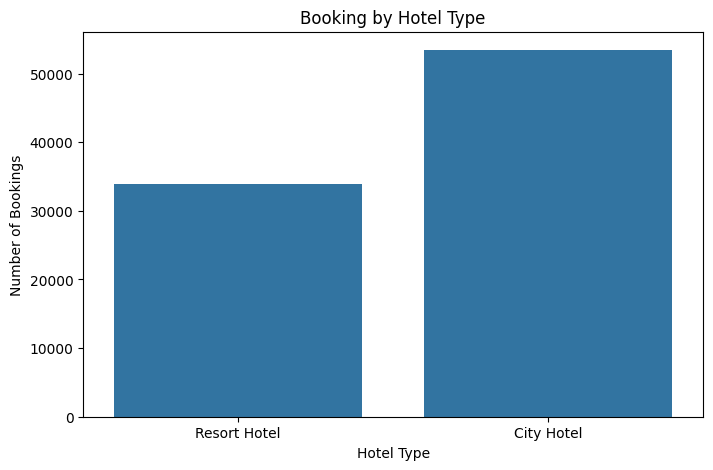

In [ ]:
#booking by hotel type-barplot to understand booking count for each hotel type

plt.figure(figsize=(8, 5))

sns.barplot(
    data=df,
    x='hotel',
    y='is_canceled',
    estimator=len
)

plt.title('Booking by Hotel Type')
plt.xlabel('Hotel Type')
plt.ylabel('Number of Bookings')

plt.show()


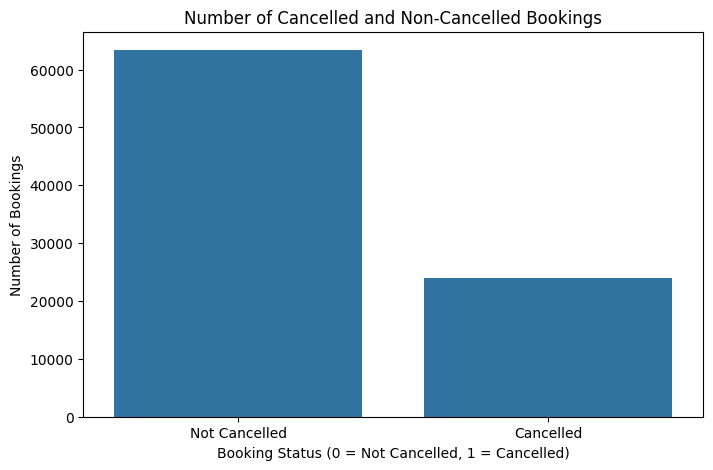

In [ ]:
# count plot - number of cancelled and non cancelled bookings-understand overall cancellation pattern

plt.figure(figsize=(8, 5))

sns.countplot(data=df, x='is_canceled')

plt.title('Number of Cancelled and Non-Cancelled Bookings')
plt.xlabel('Booking Status (0 = Not Cancelled, 1 = Cancelled)')
plt.ylabel('Number of Bookings')

plt.xticks([0, 1], ['Not Cancelled', 'Cancelled'])

plt.show()


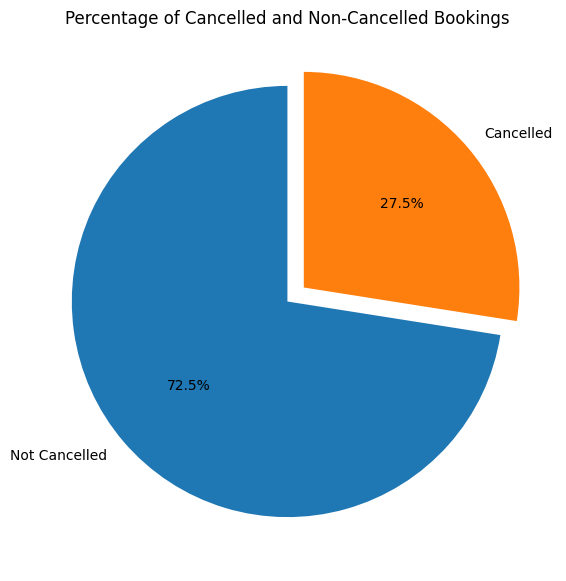

In [ ]:
#pie chart
# Calculate booking cancellation percentages-easy to understand overview of cancellation status
cancellation_counts = df['is_canceled'].value_counts().sort_index()

labels = ['Not Cancelled', 'Cancelled']
sizes = [
    cancellation_counts.get(0, 0),
    cancellation_counts.get(1, 0)
]

plt.figure(figsize=(7, 7))

plt.pie(
    sizes,
    labels=labels,
    autopct='%1.1f%%',
    startangle=90,
    explode=(0, 0.1)
)

plt.title('Percentage of Cancelled and Non-Cancelled Bookings')
plt.show()



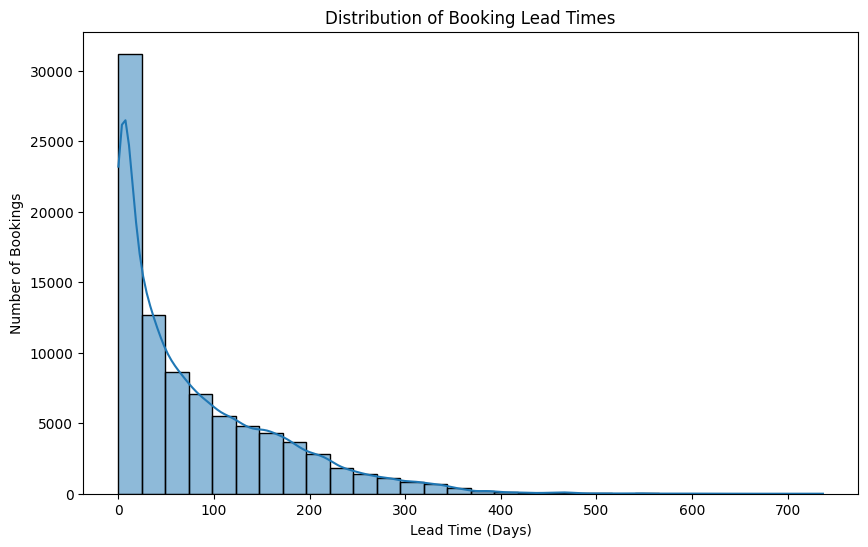

In [ ]:
#histogram:distribution of booking lead times-how far in adavance customers make their reservation

plt.figure(figsize=(10, 6))

sns.histplot(data=df, x='lead_time', bins=30, kde=True)

plt.title('Distribution of Booking Lead Times')
plt.xlabel('Lead Time (Days)')
plt.ylabel('Number of Bookings')

plt.show()


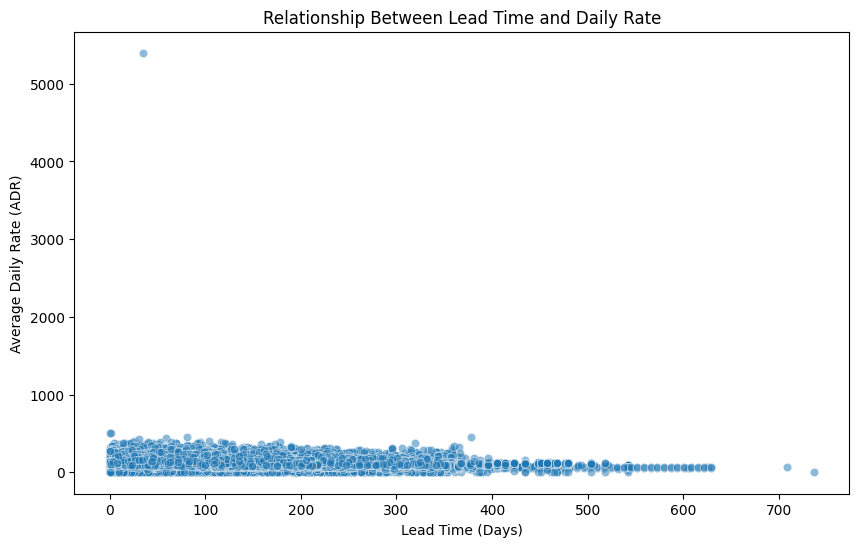

In [ ]:
#scatter plot-visible pattern between how early a booking is made and the recorded daily rate
plt.figure(figsize=(10, 6))

sns.scatterplot(data=df, x='lead_time', y='adr', alpha=0.5)

plt.title('Relationship Between Lead Time and Daily Rate')
plt.xlabel('Lead Time (Days)')
plt.ylabel('Average Daily Rate (ADR)')

plt.show()


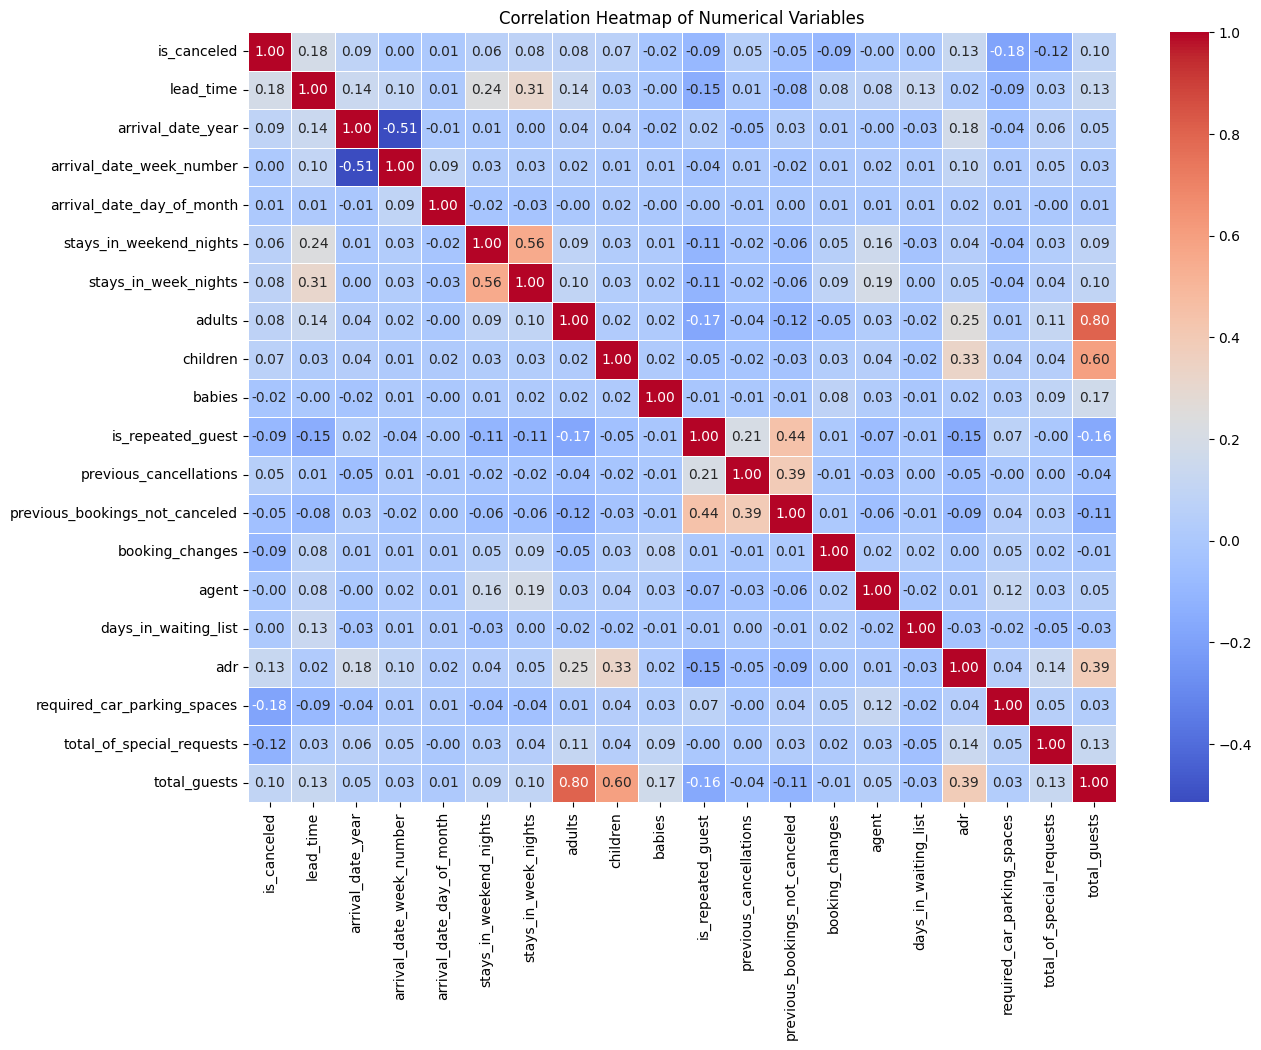

In [ ]:
#heatmap-visualize the realtionship between the numerical variables
# -helps understand positive and negative association

# Select numerical columns
numerical_df = df.select_dtypes(include=['number'])

# Calculate correlation
correlation = numerical_df.corr()

# Plot heatmap
plt.figure(figsize=(14, 10))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Heatmap of Numerical Variables')
plt.show()


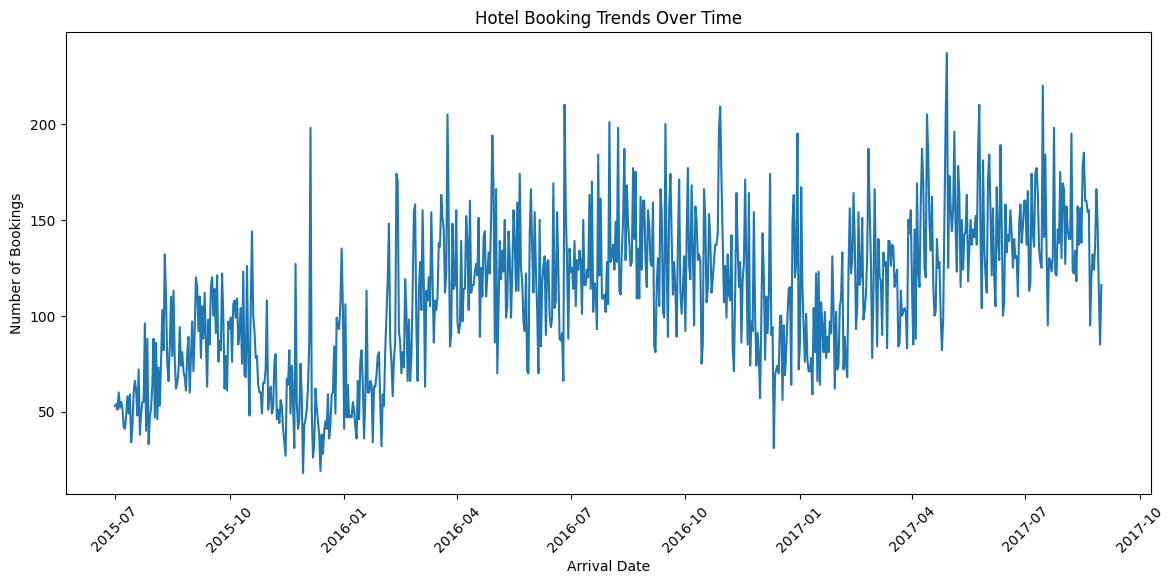

In [ ]:
#line plot-how booking volumes changes over time

# Group bookings by arrival date
daily_bookings = df.groupby('arrival_date').size().reset_index(name='booking_count')

# Sort dates
daily_bookings = daily_bookings.sort_values('arrival_date')

# Plot line graph
plt.figure(figsize=(14, 6))

sns.lineplot(
    data=daily_bookings,
    x='arrival_date',
    y='booking_count'
)

plt.title('Hotel Booking Trends Over Time')
plt.xlabel('Arrival Date')
plt.ylabel('Number of Bookings')
plt.xticks(rotation=45)

plt.show()

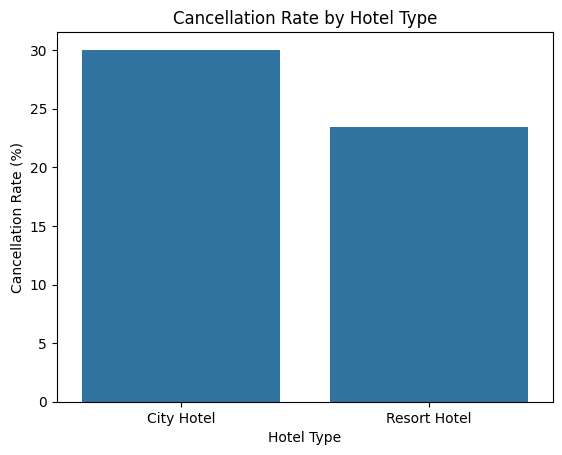

In [ ]:
#cancellation rate by hotel type

cancellation_by_hotel = (
    df.groupby('hotel')['is_canceled'].mean() * 100
).reset_index()

cancellation_by_hotel.columns = [
    'hotel', 'cancellation_rate'

]

sns.barplot(
    data=cancellation_by_hotel,
    x='hotel',
    y='cancellation_rate'
)

plt.title('Cancellation Rate by Hotel Type')
plt.xlabel('Hotel Type')
plt.ylabel('Cancellation Rate (%)')
plt.show()

In [ ]:
#cancellation rate by market segment

market_analysis = (
    df.groupby('market_segment')['is_canceled'].mean() * 100
).sort_values(ascending=False)

print(market_analysis)

market_segment
Online TA        35.348702
Groups           27.013355
Aviation         19.823789
Offline TA/TO    14.853481
Direct           14.715351
Complementary    12.535613
Corporate        12.108262
Name: is_canceled, dtype: float64


In [ ]:
# Cancellation Rate by Lead Time

df['lead_time_group'] = pd.cut(
    df['lead_time'],
    bins=[-1, 7, 30, 90, float('inf')],
    labels=['0-7 Days', '8-30 Days',
            '31-90 Days', 'Above 90 Days']
)

lead_cancellation = (
    df.groupby('lead_time_group', observed=False)['is_canceled']
    .mean() * 100
)

print(lead_cancellation)

lead_time_group
0-7 Days          8.429851
8-30 Days        25.367197
31-90 Days       32.008442
Above 90 Days    36.846841
Name: is_canceled, dtype: float64


In [ ]:
#overall cancellation rate
total_bookings = len(df)

total_cancellations = df['is_canceled'].sum()

cancellation_rate = (
    total_cancellations / total_bookings
) * 100

print("Total Bookings:", total_bookings)
print("Total Cancellations:", total_cancellations)
print("Cancellation Rate:", round(cancellation_rate, 2), "%")

Total Bookings: 87396
Total Cancellations: 24025
Cancellation Rate: 27.49 %
